In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

In [ ]:
df=pd.read_excel('/content/drive/MyDrive/Online Retail.xlsx')

In [ ]:
#Data_Understanding

In [ ]:
print("Dataset shape",df.shape)

Dataset shape (541909, 8)


In [ ]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [ ]:
df.tail()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


In [ ]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB
None


In [ ]:
print(df.describe(include="all"))

        InvoiceNo StockCode                         Description  \
count    541909.0    541909                              540455   
unique    25900.0      4070                                4223   
top      573585.0    85123A  WHITE HANGING HEART T-LIGHT HOLDER   
freq       1114.0      2313                                2369   
mean          NaN       NaN                                 NaN   
min           NaN       NaN                                 NaN   
25%           NaN       NaN                                 NaN   
50%           NaN       NaN                                 NaN   
75%           NaN       NaN                                 NaN   
max           NaN       NaN                                 NaN   
std           NaN       NaN                                 NaN   

             Quantity                    InvoiceDate      UnitPrice  \
count   541909.000000                         541909  541909.000000   
unique            NaN                            NaN 

In [ ]:
print(df.columns)

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')


In [ ]:
#Data_Quality_Checking

In [ ]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nMissing CustomerID:")
print(df["CustomerID"].isnull().sum())

print("\nMissing Description:")
print(df["Description"].isnull().sum())

print("\nNegative Quantity:")
print((df["Quantity"] < 0).sum())

print("\nZero Quantity:")
print((df["Quantity"] == 0).sum())

print("\nNegative UnitPrice:")
print((df["UnitPrice"] < 0).sum())

print("\nZero UnitPrice:")
print((df["UnitPrice"] == 0).sum())

print("\nCancellation Records:")
print(df["InvoiceNo"].astype(str).str.startswith("C").sum())

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate Rows:
5268

Missing CustomerID:
135080

Missing Description:
1454

Negative Quantity:
10624

Zero Quantity:
0

Negative UnitPrice:
2

Zero UnitPrice:
2515

Cancellation Records:
9288


In [ ]:
#Data_Cleaning_And_Preparation

In [ ]:
raw_rows = len(df)
duplicate_rows = df.duplicated().sum()
missing_customer = df["CustomerID"].isnull().sum()
missing_description = df["Description"].isnull().sum()

cancellation_mask = df["InvoiceNo"].astype(str).str.startswith("C")
cancellation_rows = cancellation_mask.sum()

df = df.drop_duplicates().copy()
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

sales = df[
    (~df["InvoiceNo"].astype(str).str.startswith("C")) &
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0) &
    (df["InvoiceDate"].notna())
].copy()

customer_sales = sales[sales["CustomerID"].notna()].copy()

print("Raw rows:", raw_rows)
print("Duplicate rows found:", duplicate_rows)
print("Rows after removing duplicates:", len(df))
print("Missing CustomerID:", missing_customer)
print("Missing Description:", missing_description)
print("Cancellation rows:", cancellation_rows)
print("Valid sales rows:", len(sales))
print("Rows excluded from sales analysis:",len(df) - len(sales))

Raw rows: 541909
Duplicate rows found: 5268
Rows after removing duplicates: 536641
Missing CustomerID: 135080
Missing Description: 1454
Cancellation rows: 9288
Valid sales rows: 524878
Rows excluded from sales analysis: 11763


In [ ]:
#Business_Calculation/KPI'S

In [ ]:
total_revenue = sales["Revenue"].sum()
total_quantity = sales["Quantity"].sum()
total_orders = sales["InvoiceNo"].nunique()
total_customers = customer_sales["CustomerID"].nunique()
total_products = sales["StockCode"].nunique()

average_order_value = total_revenue / total_orders if total_orders else 0
revenue_per_customer = total_revenue / total_customers if total_customers else 0

print("========== BUSINESS KPIs ==========")
print("Total Revenue:", round(total_revenue, 2))
print("Total Quantity Sold:", total_quantity)
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Total Products:", total_products)
print("Average Order Value:", round(average_order_value, 2))
print("Revenue per Customer:", round(revenue_per_customer, 2))

========== BUSINESS KPIs ==========
Total Revenue: 10642110.8
Total Quantity Sold: 5572420
Total Orders: 19960
Total Customers: 4338
Total Products: 3922
Average Order Value: 533.17
Revenue per Customer: 2453.23


In [ ]:
#Sales_Performance_Over_Time

Revenue by Year:
Year
2010     821452.730
2011    9820658.074
Name: Revenue, dtype: float64

Revenue by Month:
Month
2010-12     821452.730
2011-01     689811.610
2011-02     522545.560
2011-03     716215.260
2011-04     536968.491
2011-05     769296.610
2011-06     760547.010
2011-07     718076.121
2011-08     757841.380
2011-09    1056435.192
2011-10    1151263.730
2011-11    1503866.780
2011-12     637790.330
Name: Revenue, dtype: float64

Highest Revenue Month:
2011-11 1503866.78

Lowest Revenue Month:
2011-02 522545.56


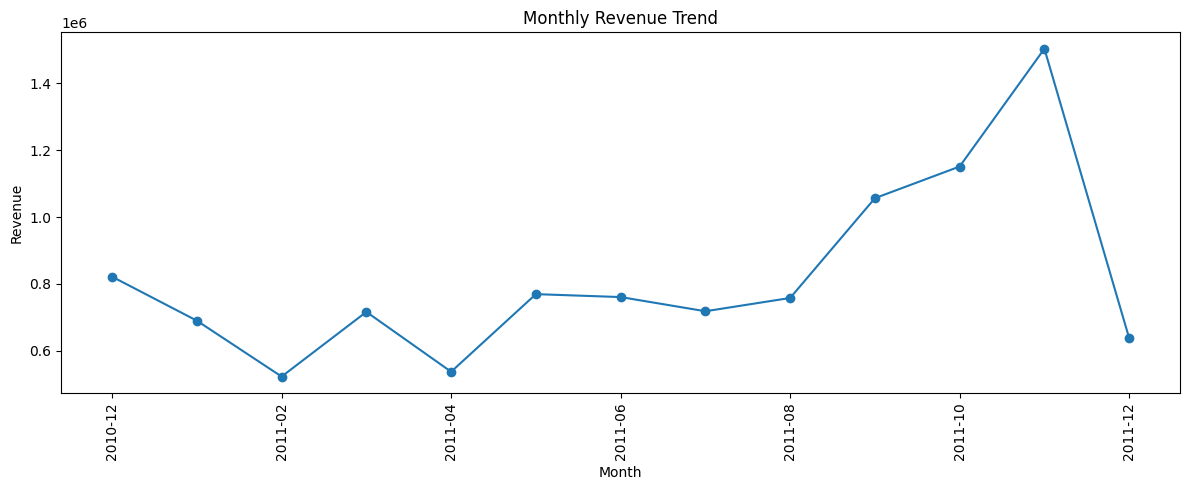

In [ ]:
sales["Year"] = sales["InvoiceDate"].dt.year
sales["Month"] = sales["InvoiceDate"].dt.to_period("M").astype(str)

yearly_revenue = sales.groupby("Year")["Revenue"].sum().sort_index()
monthly_revenue = sales.groupby("Month")["Revenue"].sum().sort_index()
monthly_orders = sales.groupby("Month")["InvoiceNo"].nunique().sort_index()
monthly_quantity = sales.groupby("Month")["Quantity"].sum().sort_index()

print("Revenue by Year:")
print(yearly_revenue)

print("\nRevenue by Month:")
print(monthly_revenue)

print("\nHighest Revenue Month:")
print(monthly_revenue.idxmax(), round(monthly_revenue.max(), 2))

print("\nLowest Revenue Month:")
print(monthly_revenue.idxmin(), round(monthly_revenue.min(), 2))

monthly_revenue.plot(kind="line", figsize=(12, 5), marker="o")

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [ ]:
#Product_Analysis

Top 10 Products by Revenue:
     StockCode                         Description    Revenue  Quantity  \
4150       DOT                      DOTCOM POSTAGE  206248.77       706   
1262     22423            REGENCY CAKESTAND 3 TIER  174156.54     13851   
2590     23843         PAPER CRAFT , LITTLE BIRDIE  168469.60     80995   
3773    85123A  WHITE HANGING HEART T-LIGHT HOLDER  104284.24     37580   
2669     47566                       PARTY BUNTING   99445.23     18283   
3761    85099B             JUMBO BAG RED RETROSPOT   94159.81     48371   
2045     23166      MEDIUM CERAMIC TOP STORAGE JAR   81700.92     78033   
4153      POST                             POSTAGE   78101.88      3150   
4151         M                              Manual   77750.27      6984   
1951     23084                  RABBIT NIGHT LIGHT   66870.03     30739   

      Orders  Revenue Share  Cumulative Revenue Share  
4150     706       1.938044                  1.938044  
1262    1988       1.636485       

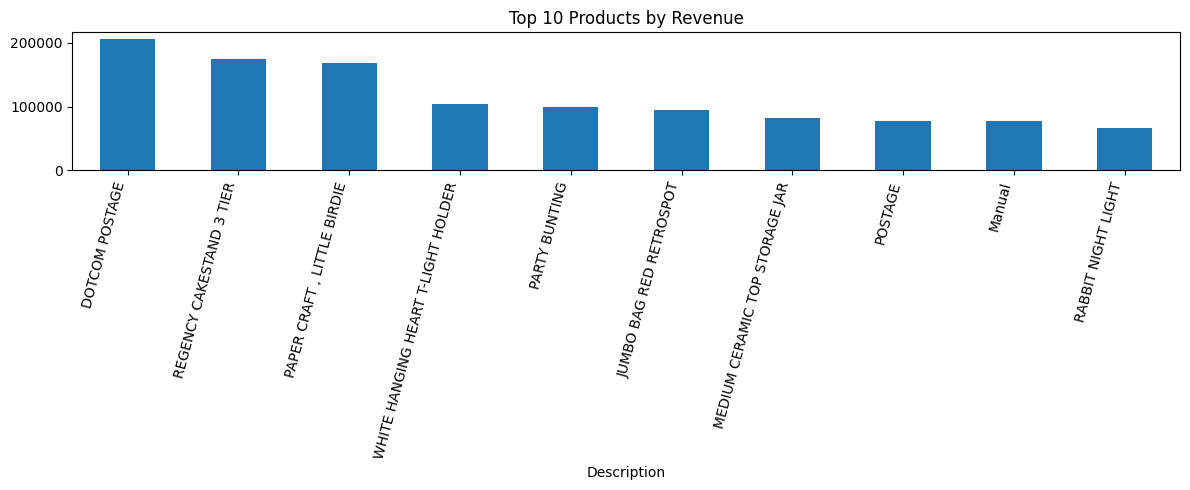

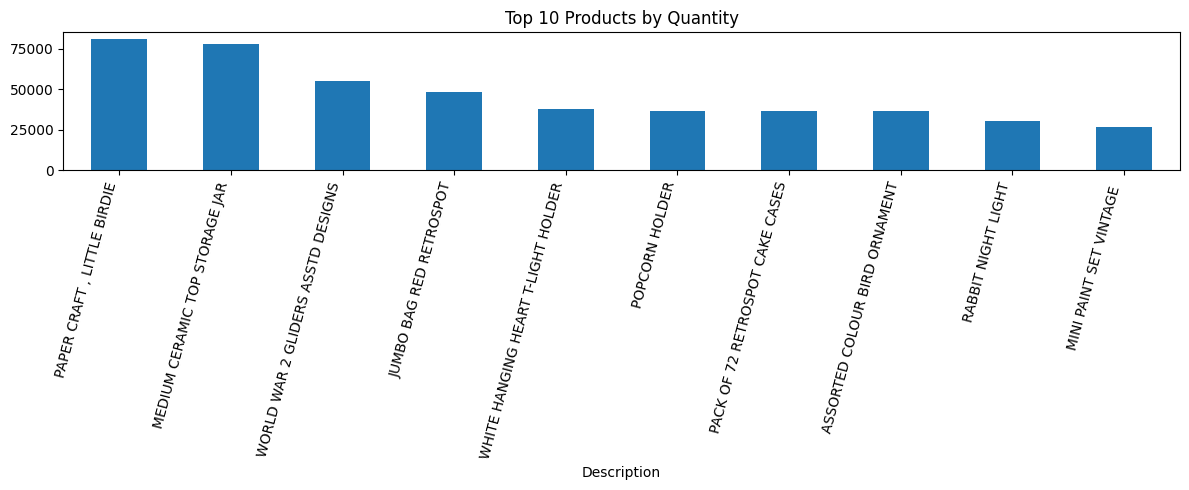

Top 20% products revenue share (%): 79.88


In [ ]:
product_analysis = sales.groupby(
    ["StockCode", "Description"], dropna=False
).agg(
    Revenue=("Revenue", "sum"),
    Quantity=("Quantity", "sum"),
    Orders=("InvoiceNo", "nunique")
).reset_index()

product_analysis["Revenue Share"] = (
    product_analysis["Revenue"] / total_revenue * 100)

product_analysis = product_analysis.sort_values(
    "Revenue", ascending=False)

product_analysis["Cumulative Revenue Share"] = (
    product_analysis["Revenue Share"].cumsum())

print("Top 10 Products by Revenue:")
print(product_analysis.head(10))

print("\nTop 10 Products by Quantity:")
print(product_analysis.sort_values("Quantity", ascending=False).head(10))

product_analysis.head(10).plot(
    x="Description", y="Revenue", kind="bar",
    figsize=(12, 5), legend=False)

plt.title("Top 10 Products by Revenue")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

product_analysis.sort_values("Quantity", ascending=False).head(10).plot(
    x="Description", y="Quantity", kind="bar",
    figsize=(12, 5), legend=False)

plt.title("Top 10 Products by Quantity")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

# Pareto Analysis
top_20_products = int(len(product_analysis) * 0.20)
pareto_revenue = product_analysis.head(top_20_products)["Revenue"].sum()
pareto_share = pareto_revenue / total_revenue * 100
print("Top 20% products revenue share (%):", round(pareto_share, 2))

In [ ]:
#Customer_Analysis

Total Customers: 4338
One-Time Customers: 1493
Repeat Customers: 2845

Top 10 Customers by Revenue:
      CustomerID  Orders  Quantity    Revenue  Average Order Value
1689     14646.0      73    196915  280206.02          3838.438630
4201     18102.0      60     64124  259657.30          4327.621667
3728     17450.0      46     69973  194390.79          4225.886739
3008     16446.0       2     80997  168472.50         84236.250000
1879     14911.0     201     80240  143711.17           714.980945
55       12415.0      21     77374  124914.53          5948.310952
1333     14156.0      55     57768  117210.08          2131.092364
3771     17511.0      31     64549   91062.38          2937.496129
2702     16029.0      63     40108   80850.84          1283.346667
0        12346.0       1     74215   77183.60         77183.600000
Top 10 Customers Revenue Share (%): 14.45


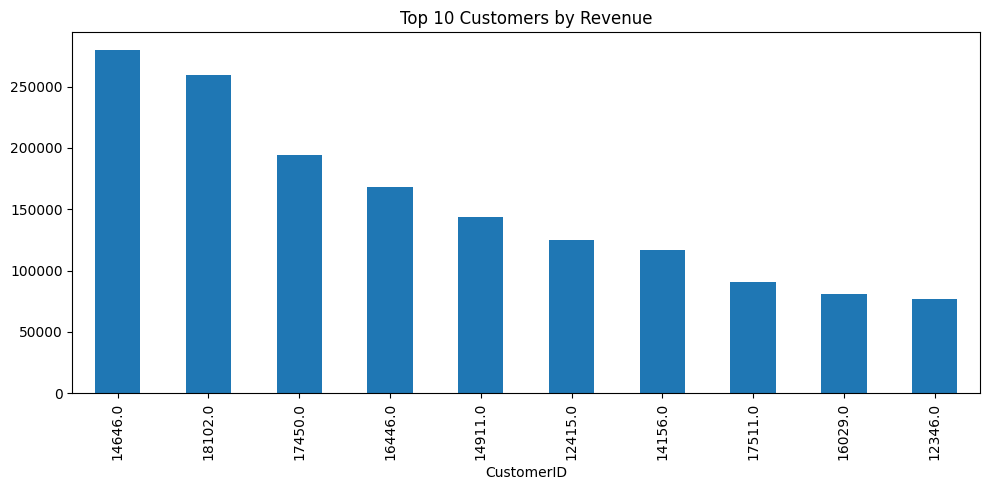

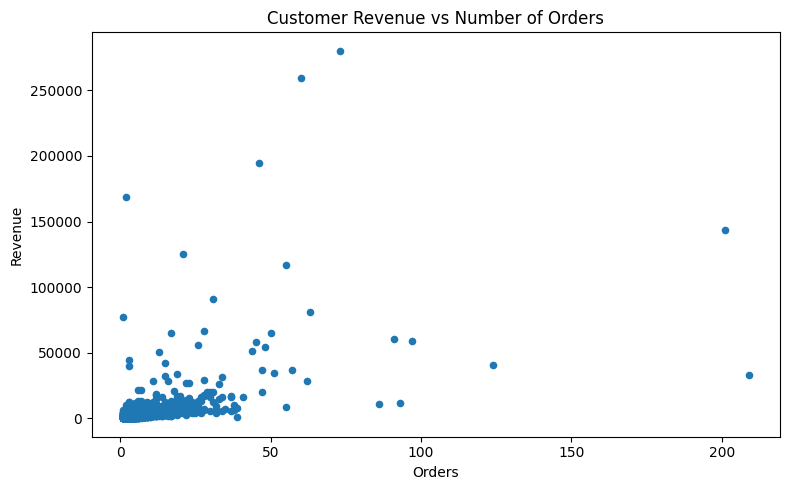

In [ ]:
customer_analysis = customer_sales.groupby("CustomerID").agg(
    Orders=("InvoiceNo", "nunique"),
    Quantity=("Quantity", "sum"),
    Revenue=("Revenue", "sum")
).reset_index()

customer_analysis["Average Order Value"] = (
    customer_analysis["Revenue"] / customer_analysis["Orders"])

one_time_customers = (customer_analysis["Orders"] == 1).sum()
repeat_customers = (customer_analysis["Orders"] > 1).sum()

print("Total Customers:", customer_analysis["CustomerID"].nunique())
print("One-Time Customers:", one_time_customers)
print("Repeat Customers:", repeat_customers)

print("\nTop 10 Customers by Revenue:")
print(customer_analysis.sort_values("Revenue", ascending=False).head(10))

top_10_customer_revenue = customer_analysis.nlargest(10, "Revenue")["Revenue"].sum()
top_10_customer_share = top_10_customer_revenue / total_revenue * 100

print("Top 10 Customers Revenue Share (%):", round(top_10_customer_share, 2))

customer_analysis.sort_values("Revenue", ascending=False).head(10).plot(
    x="CustomerID", y="Revenue", kind="bar",
    figsize=(10, 5), legend=False)

plt.title("Top 10 Customers by Revenue")
plt.tight_layout()
plt.show()

customer_analysis.plot(
    x="Orders", y="Revenue", kind="scatter", figsize=(8, 5))

plt.title("Customer Revenue vs Number of Orders")
plt.tight_layout()
plt.show()

In [ ]:
#Country/Market_Analysis

Top 10 Countries by Revenue:
           Country      Revenue  Orders  Customers  Quantity  \
36  United Kingdom  9001744.094   18019       3920   4646906   
24     Netherlands   285446.340      94          9    200361   
10            EIRE   283140.520     288          3    147007   
14         Germany   228678.400     457         94    119154   
13          France   209625.370     392         87    112060   
0        Australia   138453.810      57          9     83891   
31           Spain    61558.560      90         30     27933   
33     Switzerland    57067.600      54         21     30617   
3          Belgium    41196.340      98         25     23237   
32          Sweden    38367.830      36          8     36078   

    Average Order Value  
36           499.569571  
24          3036.663191  
10           983.126806  
14           500.390372  
13           534.758597  
0           2429.014211  
31           683.984000  
33          1056.807407  
3            420.370816  
32    

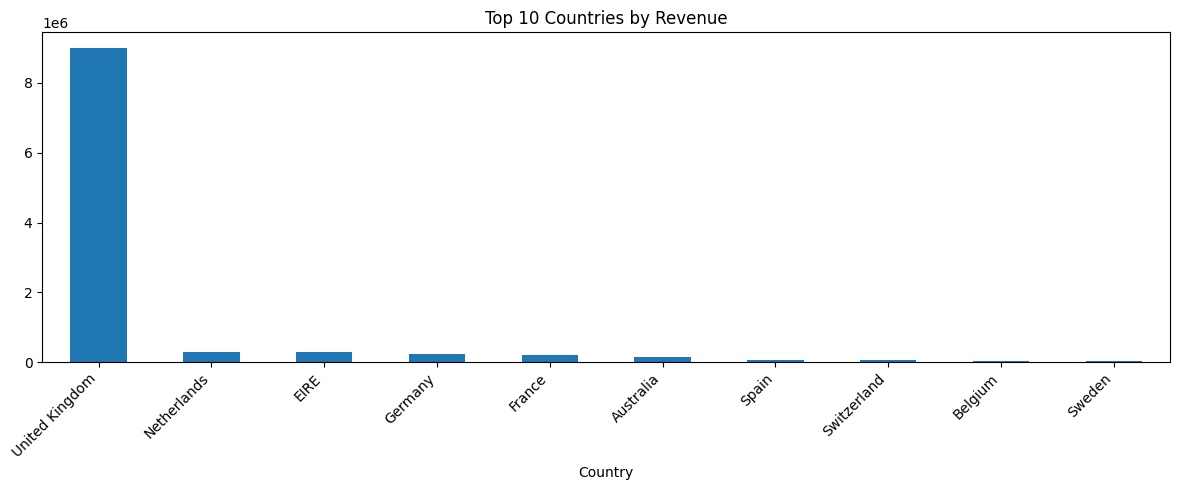

In [ ]:
country_analysis = sales.groupby("Country").agg(
    Revenue=("Revenue", "sum"),
    Orders=("InvoiceNo", "nunique"),
    Customers=("CustomerID", "nunique"),
    Quantity=("Quantity", "sum")
).reset_index()

country_analysis["Average Order Value"] = (
    country_analysis["Revenue"] /
    country_analysis["Orders"].replace(0, float("nan")))

country_analysis = country_analysis.sort_values(
    "Revenue", ascending=False)

print("Top 10 Countries by Revenue:")
print(country_analysis.head(10))

country_analysis.head(10).plot(
    x="Country", y="Revenue", kind="bar",
    figsize=(12, 5), legend=False)

plt.title("Top 10 Countries by Revenue")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
#Times_And_Operational_Analysis

Orders by Day of Week:
Weekday
Monday       3126.0
Tuesday      3554.0
Wednesday    3690.0
Thursday     4246.0
Friday       3140.0
Saturday        NaN
Sunday       2204.0
Name: InvoiceNo, dtype: float64

Orders by Hour:
Hour
6        1
7       29
8      566
9     1484
10    2361
11    2396
12    3220
13    2753
14    2457
15    2336
16    1335
17     667
18     192
19     146
20      18
Name: InvoiceNo, dtype: int64


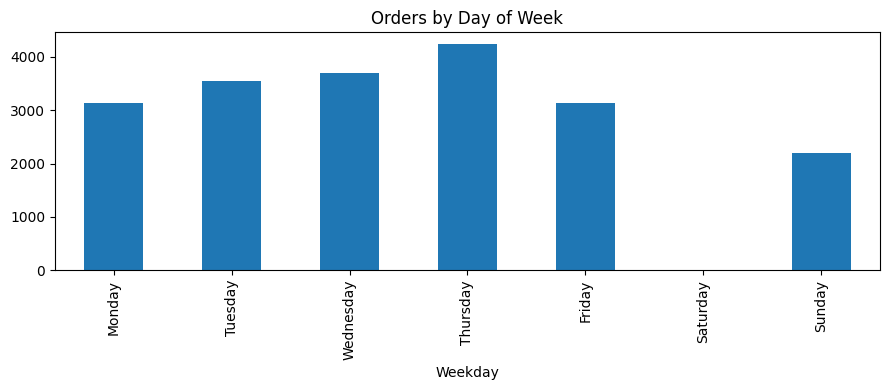

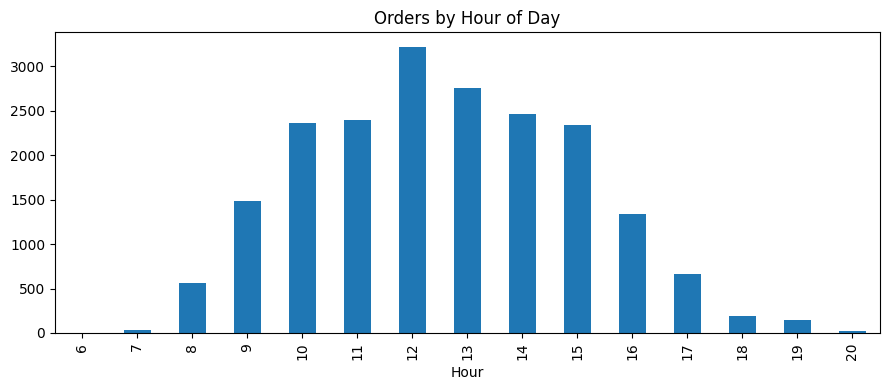

In [ ]:
sales["Weekday"] = sales["InvoiceDate"].dt.day_name()
sales["Hour"] = sales["InvoiceDate"].dt.hour

weekday_orders = sales.groupby("Weekday")["InvoiceNo"].nunique()
weekday_orders = weekday_orders.reindex([
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"])

hour_orders = sales.groupby("Hour")["InvoiceNo"].nunique()

print("Orders by Day of Week:")
print(weekday_orders)

print("\nOrders by Hour:")
print(hour_orders)

weekday_orders.plot(kind="bar", figsize=(9, 4))

plt.title("Orders by Day of Week")
plt.tight_layout()
plt.show()

hour_orders.plot(kind="bar", figsize=(9, 4))

plt.title("Orders by Hour of Day")
plt.tight_layout()
plt.show()

In [ ]:
#Cancellation_Analysis

In [ ]:
cancellations = df[
    df["InvoiceNo"].astype(str).str.startswith("C")
].copy()

cancelled_orders = cancellations["InvoiceNo"].nunique()
cancelled_rows = len(cancellations)
cancelled_quantity = cancellations["Quantity"].abs().sum()

total_invoices = df["InvoiceNo"].nunique()
cancellation_rate = cancelled_orders / total_invoices * 100

print("Cancellation Rows:", cancelled_rows)
print("Cancelled Invoice Count:", cancelled_orders)
print("Absolute Cancelled Quantity:", cancelled_quantity)
print("Cancellation Rate (%):", round(cancellation_rate, 2))

if not cancellations.empty:
    cancellations["Cancellation Month"] = (
        cancellations["InvoiceDate"].dt.to_period("M").astype(str))
    cancellations["Cancellation Hour"] = cancellations["InvoiceDate"].dt.hour

    print("\nCancellation Rows by Month:")
    print(cancellations.groupby("Cancellation Month").size())

    print("\nCancellation Rows by Hour:")
    print(cancellations.groupby("Cancellation Hour").size())

    top_cancelled_products = (
        cancellations.groupby("Description")["Quantity"]
        .sum()
        .abs()
        .sort_values(ascending=False)
        .head(10) )

    print("\nTop 10 Cancelled Products:")
    print(top_cancelled_products)

Cancellation Rows: 9251
Cancelled Invoice Count: 3836
Absolute Cancelled Quantity: 275560
Cancellation Rate (%): 14.81

Cancellation Rows by Month:
Cancellation Month
2010-12     719
2011-01     700
2011-02     470
2011-03     696
2011-04     558
2011-05     621
2011-06     709
2011-07     684
2011-08     667
2011-09     801
2011-10    1194
2011-11    1073
2011-12     359
dtype: int64

Cancellation Rows by Hour:
Cancellation Hour
6       40
7        4
8      102
9      524
10    1005
11    1188
12    1336
13    1059
14    1008
15     893
16     914
17     710
18     210
19     189
20      69
dtype: int64

Top 10 Cancelled Products:
Description
PAPER CRAFT , LITTLE BIRDIE            80995
MEDIUM CERAMIC TOP STORAGE JAR         74494
ROTATING SILVER ANGELS T-LIGHT HLDR     9376
Manual                                  4066
FAIRY CAKE FLANNEL ASSORTED COLOUR      3150
WHITE HANGING HEART T-LIGHT HOLDER      2578
GIN + TONIC DIET METAL SIGN             2030
HERB MARKER BASIL                

In [ ]:
#Buiness_Findings

In [ ]:
print("========== BUSINESS FINDINGS ==========")
print("Highest revenue month:", monthly_revenue.idxmax())
print("Lowest revenue month:", monthly_revenue.idxmin())
print("Top product by revenue:", product_analysis.iloc[0]["Description"])
print("Top country by revenue:", country_analysis.iloc[0]["Country"])
print("One-time customers:", one_time_customers)
print("Repeat customers:", repeat_customers)
print("Top 20% products revenue share (%):", round(pareto_share, 2))
print("Top 10 customers revenue share (%):", round(top_10_customer_share, 2))

========== BUSINESS FINDINGS ==========
Highest revenue month: 2011-11
Lowest revenue month: 2011-02
Top product by revenue: DOTCOM POSTAGE
Top country by revenue: United Kingdom
One-time customers: 1493
Repeat customers: 2845
Top 20% products revenue share (%): 79.88
Top 10 customers revenue share (%): 14.45


In [ ]:
#Full_Excel_Download_All_Details

In [ ]:
from google import colab
data_quality = pd.DataFrame({
    "Check": [
        "Raw Rows",
        "Duplicate Rows",
        "Rows After Duplicate Removal",
        "Missing CustomerID",
        "Missing Description",
        "Negative Quantity Rows",
        "Zero Quantity Rows",
        "Negative UnitPrice Rows",
        "Zero UnitPrice Rows",
        "Cancellation Rows",
        "Cancelled Orders",
        "Valid Sales Rows",
        "Total Revenue",
        "Total Quantity Sold",
        "Total Orders",
        "Total Customers",
        "Total Products",
        "Average Order Value",
        "Revenue per Customer",
        "Cancellation Rate (%)"
    ],
    "Value": [
        raw_rows,
        duplicate_rows,
        len(df),
        missing_customer,
        missing_description,
        (df["Quantity"] < 0).sum(),
        (df["Quantity"] == 0).sum(),
        (df["UnitPrice"] < 0).sum(),
        (df["UnitPrice"] == 0).sum(),
        cancellation_rows,
        cancelled_orders,
        len(sales),
        round(total_revenue, 2),
        total_quantity,
        total_orders,
        total_customers,
        total_products,
        round(average_order_value, 2),
        round(revenue_per_customer, 2),
        round(cancellation_rate, 2)
    ]
})
monthly_analysis = pd.DataFrame({
    "Revenue": monthly_revenue,
    "Orders": monthly_orders,
    "Quantity Sold": monthly_quantity
})
top_products = product_analysis.head(10)
top_customers = customer_analysis.sort_values("Revenue", ascending=False).head(10)
cancellation_month = (
    cancellations.groupby("Cancellation Month")["InvoiceNo"]
    .nunique()
    .rename("Cancelled Orders")
    .to_frame()
)
cancellation_product = (
    cancellations.groupby("Description")["Quantity"]
    .sum()
    .abs()
    .sort_values(ascending=False)
    .head(10)
    .rename("Cancelled Quantity")
    .to_frame()
)
with pd.ExcelWriter("Online_Retail_Full_Analysis.xlsx") as writer:
    data_quality.to_excel(writer, sheet_name="Data Quality & KPIs", index=False)
    sales.to_excel(writer, sheet_name="Cleaned Sales Data", index=False)
    monthly_analysis.to_excel(writer, sheet_name="Monthly Analysis")
    product_analysis.to_excel(writer, sheet_name="Product Analysis", index=False)
    top_products.to_excel(writer, sheet_name="Top 10 Products", index=False)
    customer_analysis.to_excel(writer, sheet_name="Customer Analysis", index=False)
    top_customers.to_excel(writer, sheet_name="Top 10 Customers", index=False)
    country_analysis.to_excel(writer, sheet_name="Country Analysis", index=False)
    weekday_orders.rename("Orders").to_frame().to_excel(writer, sheet_name="Weekday Analysis")
    hour_orders.rename("Orders").to_frame().to_excel(writer, sheet_name="Hourly Analysis")
    cancellation_month.to_excel(writer, sheet_name="Cancellations by Month")
    cancellation_product.to_excel(writer, sheet_name="Top Cancelled Products")

print("Full Excel analysis file created successfully.")
files.download("Online_Retail_Full_Analysis.xlsx")

Full Excel analysis file created successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>